# SolarSense: EDA e modelo temporário (energia por hora)

**Dados reais.** O alvo é a energia gerada a cada hora pela usina FRANCISCO (36 kWp, Jaboatão dos Guararapes/PE),
calculada a partir do histórico do inversor Sungrow (`inverter_readings` no Postgres compartilhado). As features vêm
do clima horário da **Open-Meteo** nas coordenadas da usina (`data/raw/`). O INMET de Palmares, a ~100 km, entra só
como comparação: foi a primeira fonte testada, e a visualização 1 mostra por que foi trocado.

Este é o **modelo temporário** da disciplina: enquanto a ESP não está instalada na usina, a Open-Meteo faz o
papel dos sensores ambientais. Depois da instalação, as features passam a vir do próprio SolarSense.

O tratamento usado aqui é o mesmo do treino (`src/features.py`, `src/weather.py`), e os resultados dos
modelos são lidos do MLflow, gerados por `python src/train.py`.

In [1]:
import sys
sys.path.insert(0, "../src")

from pathlib import Path

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import seaborn as sns

from db import get_engine, load_installed_power_kw, load_inverter_yield, load_max_ac_power_kw
from features import (
    FEATURE_COLUMNS, FROZEN_COUNTER_RADIATION_WH_M2, LOCAL_TZ, MIN_DAILY_ENERGY_WH, MIN_DAYLIGHT_RADIATION_WH_M2, TARGET_COLUMN,
    build_hourly_dataset, fill_counter_gaps, hourly_energy, trusted_hourly_energy,
)
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit
from weather import load_inmet_hourly, load_open_meteo_hourly

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.2f}".format)

SYSTEM_ID = "cb61394e-f4de-4273-a4b5-768d3900d900"
engine = get_engine()

## 1. Leitura das bases

In [2]:
installed_kw = load_installed_power_kw(SYSTEM_ID, engine)
max_ac_kw = load_max_ac_power_kw(SYSTEM_ID, engine)
total_yield = load_inverter_yield(SYSTEM_ID, engine)
weather = load_open_meteo_hourly()
inmet = load_inmet_hourly()

print(f"Inversor:   {len(total_yield):,} leituras de 5 em 5 min, "
      f"{total_yield.index.min():%d/%m/%Y} a {total_yield.index.max():%d/%m/%Y}; "
      f"{installed_kw:.0f} kWp instalados, potência AC máxima registrada {max_ac_kw:.1f} kW")
print(f"Open-Meteo: {len(weather):,} horas, {weather.index.min():%d/%m/%Y} a {weather.index.max():%d/%m/%Y}, "
      f"{int(weather.isna().sum().sum())} valores faltando")
print(f"INMET:      {len(inmet):,} horas, {inmet.index.min():%d/%m/%Y} a {inmet.index.max():%d/%m/%Y} (comparação)")
weather.head()

Inversor:   105,431 leituras de 5 em 5 min, 09/11/2025 a 10/11/2026; 36 kWp instalados, potência AC máxima registrada 28.6 kW
Open-Meteo: 8,808 horas, 08/11/2025 a 10/11/2026, 0 valores faltando
INMET:      16,056 horas, 31/12/2024 a 31/10/2026 (comparação)


,radiation_wh_m2,air_temp_c,humidity_pct,precipitation_mm,pressure_hpa,wind_speed_m_s
hour_start,,,,,,
2025-11-08 23:00:00+00:00,0.00,24.50,84,0.00,1008.90,1.60
2025-11-09 00:00:00+00:00,0.00,24.70,82,0.00,1009.00,2.03
2025-11-09 01:00:00+00:00,0.00,24.20,84,0.00,1008.40,1.63
2025-11-09 02:00:00+00:00,0.00,23.50,87,0.00,1008.10,1.53
2025-11-09 03:00:00+00:00,0.00,23.60,87,0.00,1007.40,1.31


## 2. Estatísticas descritivas

In [3]:
weather.describe().T

,count,mean,std,min,25%,50%,75%,max
radiation_wh_m2,8808.00,249.61,324.13,0.00,0.00,11.00,520.00,1036.00
air_temp_c,8808.00,25.54,2.42,19.70,23.60,25.10,27.40,32.80
humidity_pct,8808.00,79.44,12.47,44.00,70.00,81.00,90.00,100.00
precipitation_mm,8808.00,0.16,0.55,0.00,0.00,0.00,0.10,16.30
pressure_hpa,8808.00,1008.67,2.23,1001.70,1007.00,1008.60,1010.30,1014.90
wind_speed_m_s,8808.00,2.96,1.24,0.05,2.01,2.85,3.96,7.02


In [4]:
steps = total_yield.diff().dropna()
print("Passo do contador total_yield_wh entre leituras (Wh):")
steps.describe()

Passo do contador total_yield_wh entre leituras (Wh):


count    105430.00
mean        525.84
std        5827.05
min       -2800.00
25%           0.00
50%           0.00
75%        1000.00
max     1822200.00
Name: total_yield_wh, dtype: float64

## 3. Tratamento dos dados

1. **Energia por hora** = contador `total_yield_wh` na virada da próxima hora menos o desta (UTC).
2. Deltas negativos ou acima da maior potência AC que o inversor já entregou (28,6 kW, ou seja, 28,6 kWh numa
   hora) são impossíveis: são saltos do contador depois de buracos nos dados, e são descartados.
3. **Dias de pane** (menos de 1 kWh no dia inteiro) saem: são inversor desligado ou falta de dado, não clima.
4. A Open-Meteo (e o INMET) carimba cada valor no **fim** da hora, por isso o recuo de 1 h (justificado na visualização 4).
5. Ficam só as **horas de dia**: radiação acima de 2 Wh/m² ou alguma geração. A noite é zero trivial e inflaria as métricas.
6. **Contador parado**: hora de dia claro (radiação > 50 Wh/m²) com geração zero sai da base. Isso acontece
   nos mesmos dias dos saltos do item 2: o inversor congela o contador por algumas horas e depois pula tudo de uma vez.
7. **Fonte do clima:** Open-Meteo nas coordenadas da usina, completa (nenhum valor faltando). O INMET de Palmares foi
   descartado como fonte (visualizações 1 e 2).
8. **Features:** radiação, temperatura do ar, hora local e época do ano (seno/cosseno do dia do ano). Umidade, pressão,
   vento e chuva foram testados e não melhoram o modelo (visualização 11).
9. **Buracos de conexão** (itens 2 e 6): quando o inversor fica offline, os contadores continuam contando, então a
   energia do buraco inteiro é conhecida pelo contador **do dia** (que zera à meia-noite, então não mistura dias).
   Para o **dashboard**, ela é distribuída entre as horas do buraco proporcionalmente à radiação, sem passar dos
   28,6 kW (`fill_counter_gaps`): o total de cada dia fica igual ao do inversor. Para o **treino**, essas horas
   ficam de fora (`trusted_hourly_energy`), porque foram calculadas a partir da própria radiação e ensinariam ao
   modelo uma resposta que nós mesmos montamos. Inclui as horas em que o contador desacelerou em vez de parar
   (ex.: 11/01, 14h: 1,3 kWh com a usina a 14,7 kW, seguida de um salto de 31,6 kWh às 15h).

In [5]:
grid = pd.date_range(total_yield.index.min().ceil("h"), total_yield.index.max().floor("h"), freq="h")
counter = total_yield.reindex(grid)
raw_delta = counter.shift(-1) - counter
impossible = raw_delta[(raw_delta < 0) | (raw_delta > max_ac_kw * 1000)]
print(f"Horas com contador faltando numa das pontas: {raw_delta.isna().sum()}")
print(f"Deltas impossíveis descartados: {len(impossible)} (maior: {impossible.max() / 1000:.0f} kWh)")

daily_yield = load_inverter_yield(SYSTEM_ID, engine, counter="daily_yield_wh")
raw_energy = hourly_energy(total_yield, max_ac_kw)
rebuilt, estimated = fill_counter_gaps(daily_yield, raw_energy, weather["radiation_wh_m2"], max_ac_kw)
inverter_day = daily_yield.groupby(daily_yield.index.tz_convert(LOCAL_TZ).date).max()
rebuilt_day = rebuilt.groupby(rebuilt.index.tz_convert(LOCAL_TZ).date).sum().reindex(inverter_day.index)
print(f"Horas reconstruídas para o dashboard: {int(estimated.sum())} "
      f"({rebuilt[estimated].sum() / 1000:.0f} kWh); dias que não batem com o inversor (> 1 kWh): "
      f"{int(((rebuilt_day - inverter_day).abs() > 1000).sum())}")

energy = trusted_hourly_energy(total_yield, daily_yield, weather["radiation_wh_m2"], max_ac_kw)
daily_all = energy.groupby(energy.index.tz_convert(LOCAL_TZ).date).sum()
outage_days = daily_all[daily_all < MIN_DAILY_ENERGY_WH].index
print(f"Dias de pane (< {MIN_DAILY_ENERGY_WH / 1000:.0f} kWh): {[d.strftime('%d/%m/%Y') for d in outage_days]}")

frozen = weather.join(energy, how="inner").query(f"{TARGET_COLUMN} == 0 and radiation_wh_m2 > {FROZEN_COUNTER_RADIATION_WH_M2}")
print(f"Horas de contador parado (geração 0 com radiação > {FROZEN_COUNTER_RADIATION_WH_M2:.0f} Wh/m², contando os dias de pane): {len(frozen)}")

df = build_hourly_dataset(energy, weather)
print(f"Base final: {len(df):,} horas de dia em {df['local_date'].nunique()} dias")
df[[*FEATURE_COLUMNS, TARGET_COLUMN]].describe().T

Horas com contador faltando numa das pontas: 17
Deltas impossíveis descartados: 16 (maior: 1824 kWh)


Horas reconstruídas para o dashboard: 118 (606 kWh); dias que não batem com o inversor (> 1 kWh): 1


Dias de pane (< 1 kWh): ['09/11/2025', '10/11/2025', '11/11/2025', '12/11/2025', '13/11/2025', '14/11/2025', '15/11/2025', '16/11/2025', '17/11/2025', '28/07/2026', '10/11/2026']
Horas de contador parado (geração 0 com radiação > 50 Wh/m², contando os dias de pane): 153
Base final: 4,487 horas de dia em 356 dias


,count,mean,std,min,25%,50%,75%,max
radiation_wh_m2,4487.00,461.82,309.40,0.00,165.00,476.00,739.00,1036.00
air_temp_c,4487.00,27.01,2.18,19.70,25.50,27.20,28.60,32.80
hour,4487.00,10.96,3.73,5.00,8.00,11.00,14.00,18.00
day_of_year_sin,4487.00,0.01,0.71,-1.00,-0.68,0.03,0.72,1.00
day_of_year_cos,4487.00,-0.00,0.70,-1.00,-0.70,-0.01,0.73,1.00
energy_wh,4487.00,11556.63,8088.55,0.00,3400.00,11700.00,19400.00,27600.00


## 4. Visualizações

### Visualização 1: INMET Palmares × Open-Meteo (qual clima explica a geração?)

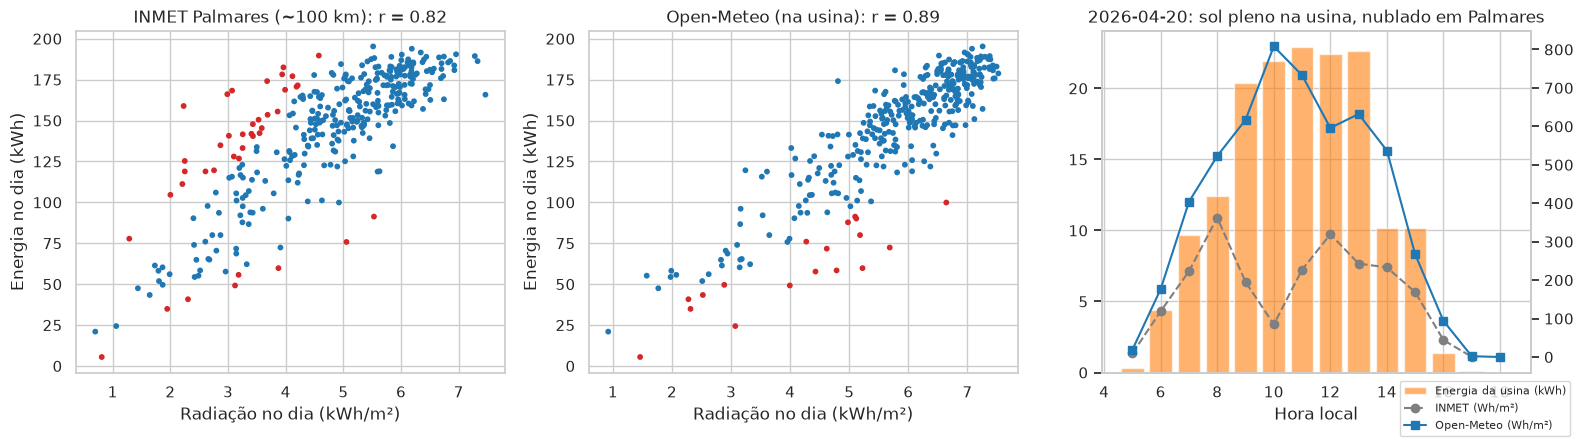

,corr. por hora,corr. por dia,"horas com PR > 1,2","dias com PR fora de 0,5–1,1"
INMET Palmares (~100 km),0.88,0.82,344.00,40.00
Open-Meteo (na usina),0.94,0.89,25.00,18.00


In [6]:
def aligned(radiation):
    return pd.concat([df[TARGET_COLUMN].rename("energy"), radiation.rename("rad")], axis=1, join="inner").dropna()

sources = {"INMET Palmares (~100 km)": aligned(inmet["radiation_wh_m2"]),
           "Open-Meteo (na usina)": aligned(weather["radiation_wh_m2"])}
rows = {}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (name, pair) in zip(axes[:2], sources.items()):
    local = pair.index.tz_convert(LOCAL_TZ).date
    day = pair.groupby(local).sum() / 1000
    day = day[day["energy"] > MIN_DAILY_ENERGY_WH / 1000]
    pr = day["energy"] / (day["rad"] * installed_kw)
    ax.scatter(day["rad"], day["energy"], s=10, c=np.where((pr < 0.5) | (pr > 1.1), "tab:red", "tab:blue"))
    ax.set_xlabel("Radiação no dia (kWh/m²)")
    ax.set_ylabel("Energia no dia (kWh)")
    ax.set_title(f"{name}: r = {day['energy'].corr(day['rad']):.2f}")
    sun = pair[pair["rad"] > 200]
    rows[name] = {"corr. por hora": pair["energy"].corr(pair["rad"]), "corr. por dia": day["energy"].corr(day["rad"]),
                  "horas com PR > 1,2": int(((sun["energy"] / 1000) / (sun["rad"] / 1000 * installed_kw) > 1.2).sum()),
                  "dias com PR fora de 0,5–1,1": int(((pr < 0.5) | (pr > 1.1)).sum())}

example = "2026-04-20"
local_index = energy.index.tz_convert(LOCAL_TZ)
mask = (local_index.strftime("%Y-%m-%d") == example) & (local_index.hour >= 5) & (local_index.hour <= 18)
hours = local_index[mask].hour
axes[2].bar(hours, energy[mask] / 1000, color="tab:orange", alpha=0.6, label="Energia da usina (kWh)")
axt = axes[2].twinx()
axt.plot(hours, inmet["radiation_wh_m2"].reindex(energy.index[mask]), "o--", color="tab:gray", label="INMET (Wh/m²)")
axt.plot(hours, weather["radiation_wh_m2"].reindex(energy.index[mask]), "s-", color="tab:blue", label="Open-Meteo (Wh/m²)")
axt.grid(False)
axes[2].set_xlabel("Hora local")
axes[2].set_title(f"{example}: sol pleno na usina, nublado em Palmares")
fig.legend(loc="lower right", bbox_to_anchor=(0.99, 0.0), fontsize=8)
plt.tight_layout()
plt.show()
pd.DataFrame(rows).T

**Interpretação:** a Open-Meteo explica a geração da usina muito melhor que o INMET. Nas mesmas horas limpas, a correlação entre energia e radiação sobe de 0,88 para 0,94 por hora e de 0,82 para 0,89 por dia. Os pontos vermelhos são dias com Performance Ratio (energia ÷ radiação × potência instalada) fora de 0,5–1,1, fisicamente improváveis: caem de 40 para 18 dias, e as horas com PR acima de 1,2 (a usina gerando mais do que o sol medido permitiria) caem de 344 para 25. O exemplo da direita mostra a causa: em 20/04 a usina gerou perto do máximo das 9h às 13h, enquanto a estação de Palmares, a ~100 km, marcava céu nublado. A Open-Meteo, calculada nas coordenadas da usina, acompanha a curva de geração.

### Visualização 2: dados faltantes no INMET por mês e o que eles significam

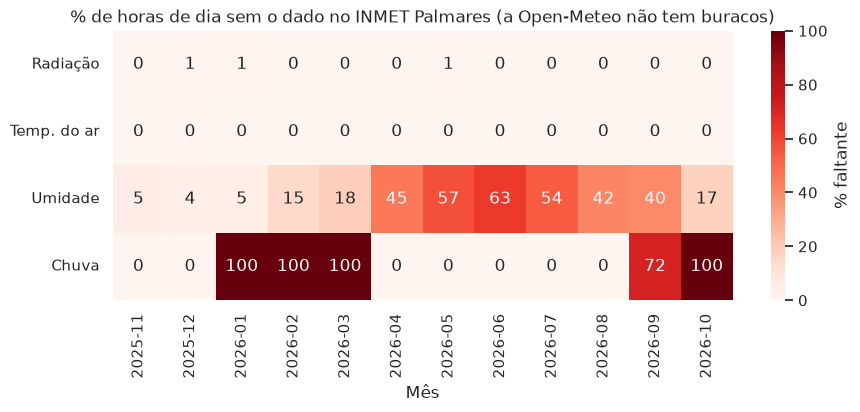

Umidade logo antes de cada buraco: mediana 100%, percentil 10 99%
Umidade observada em geral: mediana 85%


In [7]:
inmet_day = inmet.join(energy, how="inner").dropna(subset=[TARGET_COLUMN])
inmet_day = inmet_day[(inmet_day["radiation_wh_m2"] > MIN_DAYLIGHT_RADIATION_WH_M2) | (inmet_day[TARGET_COLUMN] > 0)]
cols = {"radiation_wh_m2": "Radiação", "air_temp_c": "Temp. do ar", "humidity_pct": "Umidade", "precipitation_mm": "Chuva"}
missing = inmet_day[list(cols)].isna().groupby(inmet_day.index.tz_convert(LOCAL_TZ).strftime("%Y-%m")).mean().rename(columns=cols) * 100

fig, ax = plt.subplots(figsize=(10, 3.5))
sns.heatmap(missing.T, annot=True, fmt=".0f", cmap="Reds", vmin=0, vmax=100, cbar_kws={"label": "% faltante"}, ax=ax)
ax.set_xlabel("Mês")
ax.set_ylabel("")
ax.set_title("% de horas de dia sem o dado no INMET Palmares (a Open-Meteo não tem buracos)")
plt.show()

humidity = inmet["humidity_pct"]
before_gap = humidity[humidity.notna() & humidity.shift(-1).isna()]
print(f"Umidade logo antes de cada buraco: mediana {before_gap.median():.0f}%, percentil 10 {before_gap.quantile(0.1):.0f}%")
print(f"Umidade observada em geral: mediana {humidity.median():.0f}%")

**Interpretação:** além da distância, o INMET tem buracos. A umidade falta em 41% a 63% das horas de dia de abril a setembro, e a chuva não tem nenhum registro em jan–mar e outubro. Os buracos de umidade não são aleatórios: o último valor antes de cada buraco tem mediana de 100% (contra 85% no geral), ou seja, o sensor para de registrar quando satura, nas horas mais úmidas. Preencher com média enviesaria a base. A Open-Meteo não tem nenhum valor faltando, o que permitiu testar todas as variáveis de clima no modelo (visualização 13).

### Visualização 3: energia gerada por dia ao longo do ano

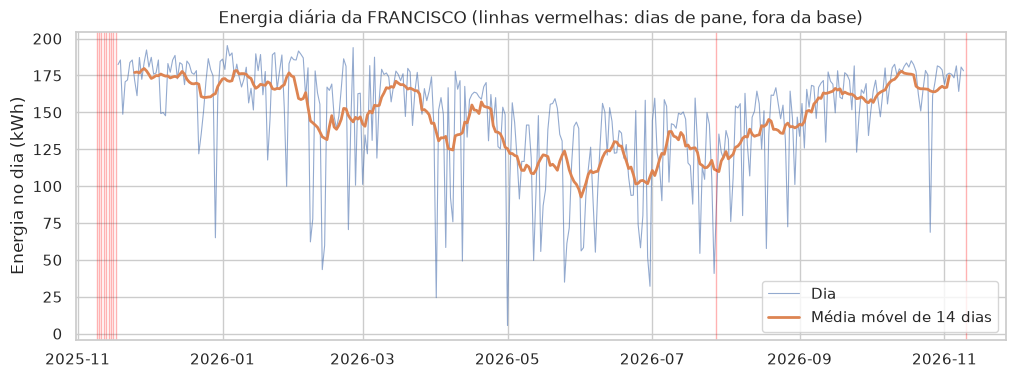

count   356.00
mean    147.21
std      37.15
min       5.50
25%     131.23
50%     158.40
75%     175.62
max     195.30
Name: daily_yield_wh, dtype: float64


In [8]:
daily = inverter_day[~inverter_day.index.isin(outage_days)] / 1000
daily = daily[pd.to_datetime(daily.index) <= pd.Timestamp(df["local_date"].max())]
daily.index = pd.to_datetime(daily.index)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(daily.index, daily.values, linewidth=0.8, alpha=0.6, label="Dia")
ax.plot(daily.rolling(14, center=True).mean(), linewidth=2, label="Média móvel de 14 dias")
for d in outage_days:
    ax.axvline(pd.Timestamp(d), color="red", alpha=0.3, linewidth=1)
ax.set_ylabel("Energia no dia (kWh)")
ax.set_title("Energia diária da FRANCISCO (linhas vermelhas: dias de pane, fora da base)")
ax.legend()
plt.show()
print(daily.describe())

**Interpretação:** a usina gera em média 147 kWh por dia (mediana de 156 kWh), segundo o total diário registrado pelo próprio inversor. Esse total é usado aqui, e não a soma das horas da base, porque nos dias com buraco de conexão a soma das horas mostraria vales que não aconteceram (item 9 do tratamento). Há uma sazonalidade clara: perto de 170–175 kWh/dia de novembro a janeiro e em outubro, caindo para 100–120 kWh/dia de abril a julho, que é a estação chuvosa da Zona da Mata pernambucana. Os dias isolados muito abaixo da média móvel são dias nublados ou chuvosos, exatamente o que o modelo precisa explicar a partir do clima. As linhas vermelhas são os dias de pane (inversor sem geração), retirados da base porque não têm relação com o tempo.

### Visualização 4: perfil médio do dia e alinhamento de horário com a Open-Meteo

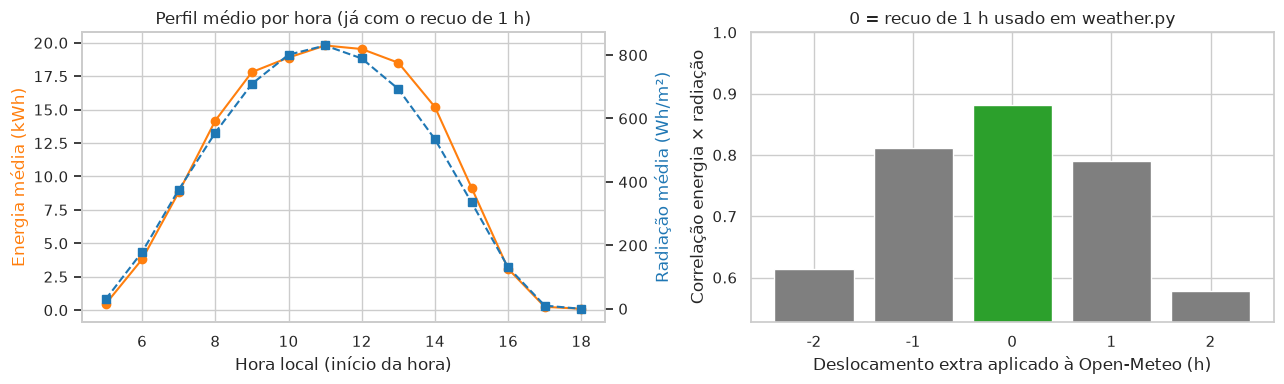

{-2: np.float64(0.615), -1: np.float64(0.812), 0: np.float64(0.882), 1: np.float64(0.79), 2: np.float64(0.578)}


In [9]:
lags = range(-2, 3)
corr = []
for lag in lags:
    shifted = weather["radiation_wh_m2"].shift(-lag, freq="h")
    pair = pd.concat([energy, shifted], axis=1, join="inner").dropna()
    pair = pair[(pair.iloc[:, 0] > 0) | (pair.iloc[:, 1] > MIN_DAYLIGHT_RADIATION_WH_M2)]
    corr.append(pair.corr().iloc[0, 1])

profile = df.groupby("hour")[[TARGET_COLUMN, "radiation_wh_m2"]].mean()

fig, (ax1, ax3) = plt.subplots(1, 2, figsize=(13, 4))
ax1.plot(profile.index, profile[TARGET_COLUMN] / 1000, "o-", color="tab:orange", label="Energia (kWh)")
ax1.set_xlabel("Hora local (início da hora)")
ax1.set_ylabel("Energia média (kWh)", color="tab:orange")
ax2 = ax1.twinx()
ax2.plot(profile.index, profile["radiation_wh_m2"], "s--", color="tab:blue", label="Radiação (Wh/m²)")
ax2.set_ylabel("Radiação média (Wh/m²)", color="tab:blue")
ax2.grid(False)
ax1.set_title("Perfil médio por hora (já com o recuo de 1 h)")

ax3.bar([str(l) for l in lags], corr, color=["tab:gray" if l != 0 else "tab:green" for l in lags])
ax3.set_xlabel("Deslocamento extra aplicado à Open-Meteo (h)")
ax3.set_ylabel("Correlação energia × radiação")
ax3.set_ylim(min(corr) - 0.05, 1)
ax3.set_title("0 = recuo de 1 h usado em weather.py")
plt.tight_layout()
plt.show()
print(dict(zip(lags, np.round(corr, 3))))

**Interpretação:** a energia horária acompanha a curva de radiação ao longo do dia, com pico entre 10h e 12h (horário local). O gráfico da direita justifica o recuo de 1 h aplicado à Open-Meteo: com ele (barra verde), a correlação entre energia e radiação é a maior (0,88), contra 0,81 sem o recuo (−1) e 0,79 recuando 2 h (+1). Isso confirma que a Open-Meteo, como o INMET, carimba cada valor no fim da hora (a radiação é a média da hora anterior). Sem esse ajuste, toda a base ficaria desalinhada em uma hora.

### Visualização 5: energia × radiação, colorida pela temperatura do ar

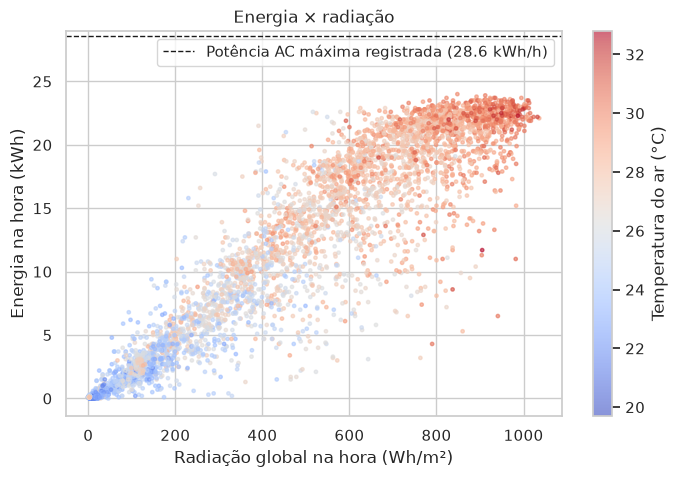

Maior energia numa hora: 27.6 kWh; percentil 99: 23.3 kWh


In [10]:
fig, ax = plt.subplots(figsize=(8, 5))
points = ax.scatter(df["radiation_wh_m2"], df[TARGET_COLUMN] / 1000, c=df["air_temp_c"], cmap="coolwarm", s=6, alpha=0.6)
fig.colorbar(points, label="Temperatura do ar (°C)")
ax.axhline(max_ac_kw, color="k", linestyle="--", linewidth=1, label=f"Potência AC máxima registrada ({max_ac_kw:.1f} kWh/h)")
ax.set_xlabel("Radiação global na hora (Wh/m²)")
ax.set_ylabel("Energia na hora (kWh)")
ax.set_title("Energia × radiação")
ax.legend()
plt.show()
print(f"Maior energia numa hora: {df[TARGET_COLUMN].max() / 1000:.1f} kWh; percentil 99: {df[TARGET_COLUMN].quantile(0.99) / 1000:.1f} kWh")

**Interpretação:** a relação é forte e crescente até cerca de 600 Wh/m². A partir daí a geração satura perto de 23 kWh por hora (percentil 99: 23,3 kWh), mesmo com radiação alta. É um teto bem abaixo dos 36 kWp instalados: a maior potência AC que o inversor já entregou foi 28,6 kW, e o patamar em 23 kWh indica limitação do inversor ou da exportação para a rede (vale confirmar com o instalador). Essa saturação não é linear, o que favorece modelos de árvore e ensembles. A linha tracejada é o limite usado na limpeza: nenhuma hora pode passar de 28,6 kWh. A cor mostra que as horas mais quentes coincidem com as de mais sol, por isso a temperatura do ar sozinha acrescenta pouca informação.

### Visualização 6: correlação entre as variáveis

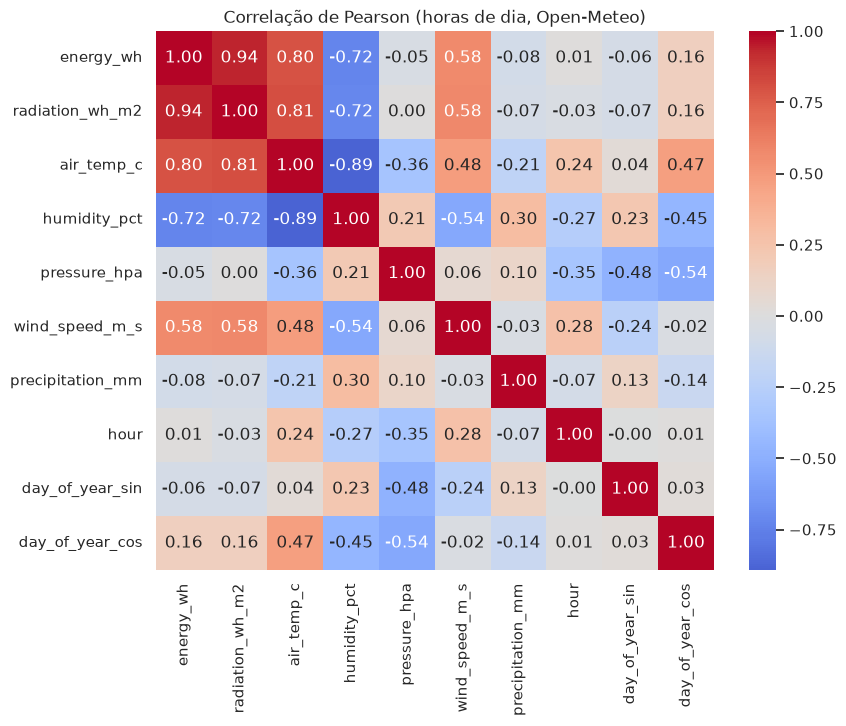

In [11]:
corr_cols = [TARGET_COLUMN, "radiation_wh_m2", "air_temp_c", "humidity_pct", "pressure_hpa", "wind_speed_m_s",
             "precipitation_mm", "hour", "day_of_year_sin", "day_of_year_cos"]
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlação de Pearson (horas de dia, Open-Meteo)")
plt.show()

**Interpretação:** a radiação é a variável mais correlacionada com a energia (0,94). A temperatura do ar também é alta (0,80), mas quase tudo vem da própria radiação (as duas têm 0,81 entre si). A umidade (−0,72) é praticamente o espelho da temperatura (−0,89), e o vento (0,57) sobe junto com o sol (brisa marítima de dia). Pressão e chuva quase não se relacionam com a energia hora a hora. Ou seja, as variáveis extras repetem informação que a radiação já traz, o que a visualização 13 confirma no modelo. A hora tem correlação linear perto de zero porque a relação é em forma de sino (visualização 4), algo que KNN, árvores e MLP capturam mas a correlação de Pearson não mede. O dia do ano (cosseno, 0,16) carrega a sazonalidade da visualização 3.

### Visualização 7: distribuição da energia por hora em cada mês

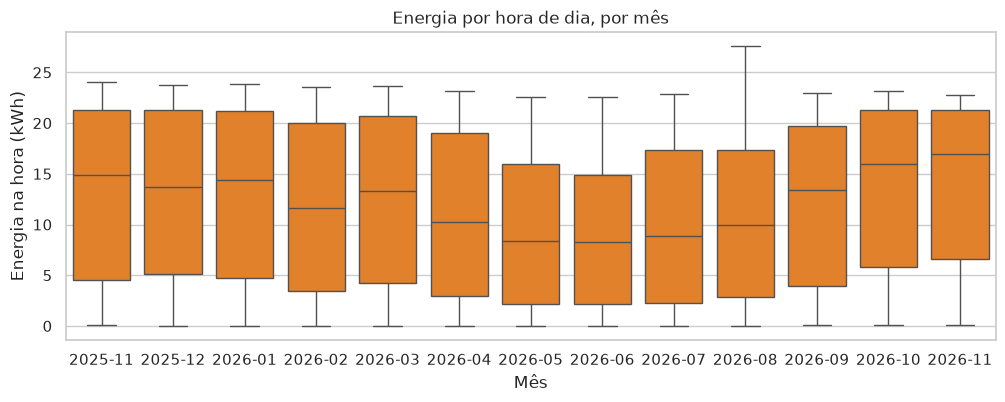

In [12]:
month = pd.to_datetime(df["local_date"]).dt.strftime("%Y-%m")
fig, ax = plt.subplots(figsize=(12, 4))
sns.boxplot(x=month, y=df[TARGET_COLUMN] / 1000, color="tab:orange", fliersize=2, ax=ax)
ax.set_xlabel("Mês")
ax.set_ylabel("Energia na hora (kWh)")
ax.set_title("Energia por hora de dia, por mês")
plt.show()

**Interpretação:** a mediana da energia por hora cai de cerca de 14–16 kWh (out–jan) para cerca de 8 kWh (mai–jul). A dispersão é grande em todos os meses porque cada caixa mistura o começo, o pico e o fim do dia. É a mesma sazonalidade da visualização 3 vista hora a hora: um modelo treinado só com meses secos superestimaria a geração no inverno chuvoso, por isso a validação respeita a ordem do tempo.

## 5. Modelos e estratégias de validação

Os resultados abaixo vêm da última execução de `python src/train.py`, lida do MLflow. Resumo do desenho:

- **Holdout temporal:** os últimos 20% dos dias são o teste. A regra de ouro da aula 04: treino no passado, teste no futuro.
- **Grid Search** em cada modelo (KNN, Árvore, Random Forest, AdaBoost, MLP), pontuado por **TimeSeriesSplit (5 folds)** no treino.
- `StandardScaler` dentro do `Pipeline`, ajustado só na parte de treino de cada fold (sem vazamento).
- Comparações:
  - **"Um dia fora"**: Leave-One-Out agrupado por dia. O LOO puro, com cerca de 3,7 mil horas no treino, seria caro e quase igual ao KFold, e a aula 04 o reserva para bases pequenas.
  - **KFold embaralhado:** mostra o quanto uma divisão aleatória superestima o modelo.
- O campeão é escolhido pelo RMSE do TimeSeriesSplit, nunca pelo teste.

**Baseline físico.** Antes de comparar modelos, é preciso saber o que se ganha com ML. O baseline é a conta que um
projetista faria sem aprender nada dos dados, além de um número:

energia na hora = radiação (Wh/m²) × 36 kWp × PR, limitada à potência máxima do inversor.

O PR (*performance ratio*) é a fração da energia ideal que chega à rede depois das perdas por calor, sujeira, cabos e
inversor. Ele é a mediana de real ÷ ideal nas horas de treino com sol (radiação ≥ 200 Wh/m²), recalculada em cada
fold, então passa pelas mesmas validações dos modelos (`src/baseline.py`). Ele não concorre a campeão: é a régua.
Um modelo só se justifica se errar claramente menos que ele.

In [13]:
import os
mlflow.set_tracking_uri(os.environ.get("MLFLOW_TRACKING_URI", "http://localhost:5000"))
runs = mlflow.search_runs(experiment_names=["solarsense-energy-hourly-openmeteo"], order_by=["start_time DESC"])
parent = runs[runs["tags.mlflow.runName"].str.startswith("compare")].iloc[0]
children = runs[runs["tags.mlflow.parentRunId"] == parent["run_id"]].set_index("tags.mlflow.runName")

print(f"Execução de {parent['start_time']:%d/%m/%Y %H:%M}: treino {parent['params.train_period']}, teste {parent['params.test_period']}, "
      f"campeão = {parent['params.champion']}")
metrics = ["train_rmse", "timeseries_train_rmse_mean", "timeseries_rmse_mean", "timeseries_rmse_std", "day_out_rmse_mean", "kfold_shuffled_rmse_mean",
           "test_mae", "test_rmse", "test_r2", "test_nrmse_pct", "test_daily_mape_pct"]
summary = children[[f"metrics.{m}" for m in metrics]].rename(columns=lambda c: c.removeprefix("metrics."))
summary.index.name = "modelo"
print(f"PR do baseline (treino): {children.loc['baseline', 'params.performance_ratio']}; "
      f"ganho do campeão sobre o baseline no TimeSeriesSplit: {parent['metrics.champion_gain_over_baseline_pct']:.0f}%")
summary.sort_values("timeseries_rmse_mean")

Execução de 10/11/2026 18:25: treino 2025-11-18..2026-08-29, teste 2026-08-30..2026-11-09, campeão = random_forest
PR do baseline (treino): 0.7149; ganho do campeão sobre o baseline no TimeSeriesSplit: 3%


,train_rmse,timeseries_train_rmse_mean,timeseries_rmse_mean,timeseries_rmse_std,day_out_rmse_mean,kfold_shuffled_rmse_mean,test_mae,test_rmse,test_r2,test_nrmse_pct,test_daily_mape_pct
modelo,,,,,,,,,,,
random_forest,2128.92,1902.52,2897.90,260.26,2391.16,2599.24,1356.35,1908.63,0.94,14.92,6.70
adaboost,2513.84,2152.30,2927.51,196.43,2490.47,2666.57,1401.76,1984.46,0.94,15.52,7.05
decision_tree,2524.14,2307.45,2970.38,158.18,2520.89,2728.78,1529.09,2116.45,0.93,16.55,7.43
baseline,2899.41,2786.39,2988.64,286.99,2661.71,2895.80,1734.02,2432.89,0.91,19.02,8.08
knn,0.00,0.00,3209.79,762.64,2409.00,2639.79,1461.24,1997.57,0.94,15.62,7.30
mlp,2571.87,2476.01,4316.91,1853.14,2443.93,2617.49,1572.53,2160.38,0.93,16.89,8.05


In [14]:
params = children[[c for c in children.columns if c.startswith("params.")]].dropna(axis=1, how="all")
params.rename(columns=lambda c: c.removeprefix("params.")).T.fillna("")

tags.mlflow.runName,mlp,adaboost,random_forest,decision_tree,knn,baseline
hidden_layer_sizes,"(64, 32)",,,,,
learning_rate_init,0.01,,,,,
alpha,0.01,,,,,
n_estimators,,50,300,,,
learning_rate,,0.05,,,,
estimator__max_depth,,5,,,,
min_samples_leaf,,,5,20,,
max_depth,,,8,6,,
weights,,,,,distance,
n_neighbors,,,,,20,


### Visualização 8: RMSE por estratégia de validação

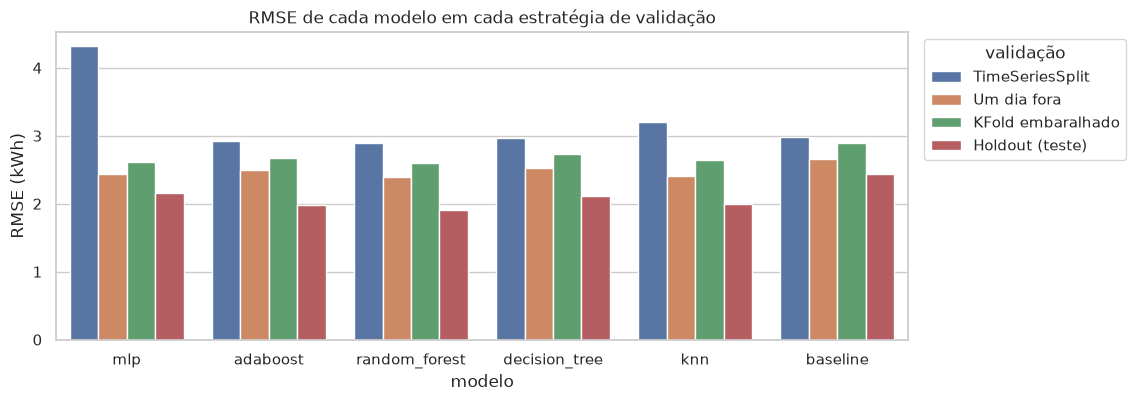

In [15]:
strategies = {"timeseries_rmse_mean": "TimeSeriesSplit", "day_out_rmse_mean": "Um dia fora",
              "kfold_shuffled_rmse_mean": "KFold embaralhado", "test_rmse": "Holdout (teste)"}
plot_df = (summary[list(strategies)].rename(columns=strategies) / 1000).reset_index().melt(id_vars="modelo", var_name="validação", value_name="RMSE (kWh)")
fig, ax = plt.subplots(figsize=(11, 4))
sns.barplot(data=plot_df, x="modelo", y="RMSE (kWh)", hue="validação", ax=ax)
ax.set_title("RMSE de cada modelo em cada estratégia de validação")
ax.legend(title="validação", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.show()

**Interpretação:** o KFold embaralhado e o "um dia fora" dão RMSE menor que o TimeSeriesSplit em todos os modelos, porque treinam com dias do futuro e de todas as estações. É o otimismo que a aula 04 alerta. O TimeSeriesSplit é o mais pessimista porque os primeiros folds treinam com pouco dado (no MLP isso pesa muito: 4,3 kWh de média). O holdout final (teste de 30/08 a 09/11) tem o menor erro: treina com quase um ano inteiro e testa num período seco e ensolarado, mais fácil de prever. Por isso o campeão é escolhido pelo TimeSeriesSplit e o teste fica só para relatar o resultado.

**Contra o baseline físico (PR de 0,71):** no TimeSeriesSplit a vantagem do campeão é pequena (2,90 contra 2,99 kWh, 3%), e o KNN e o MLP ficam piores que ele. Com pouco treino, um modelo de um parâmetro só é difícil de bater, porque a radiação explica quase tudo. A diferença aparece quando há dado suficiente: no "um dia fora" o Random Forest erra 10% menos (2,39 contra 2,66 kWh) e no teste 22% menos (1,91 contra 2,43 kWh; R² de 0,94 contra 0,91; erro no total diário de 6,7% contra 8,1%). A visualização 12 mostra de onde vem esse ganho. O Random Forest venceu nas duas frentes e é o campeão.

### Visualização 9: treino × validação (overfitting)

Erro no próprio treino ao lado do erro em dado não visto. "Treino (folds)" e "Validação (folds)" são a média dos
mesmos 5 folds do TimeSeriesSplit, então a distância entre eles mede o quanto cada modelo decorou o treino.

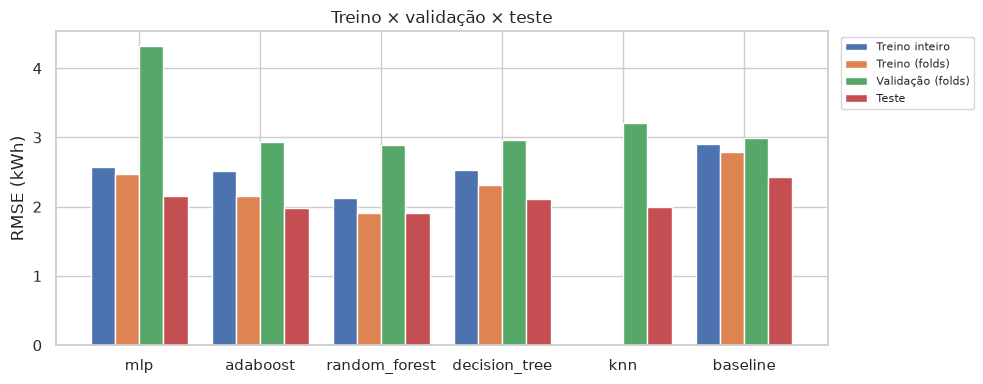

,"treino (folds, kWh)","validação (folds, kWh)",distância (kWh)
modelo,,,
baseline,2.79,2.99,0.20
decision_tree,2.31,2.97,0.66
adaboost,2.15,2.93,0.78
random_forest,1.90,2.90,1.00
mlp,2.48,4.32,1.84
knn,0.00,3.21,3.21


In [16]:
from evaluation import plot_train_vs_validation
%matplotlib inline

plot_train_vs_validation(summary)
plt.show()
gap = (summary["timeseries_rmse_mean"] - summary["timeseries_train_rmse_mean"]) / 1000
pd.DataFrame({"treino (folds, kWh)": summary["timeseries_train_rmse_mean"] / 1000,
              "validação (folds, kWh)": summary["timeseries_rmse_mean"] / 1000,
              "distância (kWh)": gap}).sort_values("distância (kWh)").round(2)

**Interpretação:** o gráfico separa os modelos em três grupos, o clássico equilíbrio entre viés e variância:

- **Baseline físico: viés alto, sem overfitting.** Erra quase igual no treino (2,79 kWh) e na validação (2,99 kWh). Com um único parâmetro, não tem como decorar o treino, mas também não aprende nada além do PR.
- **KNN: memorização pura.** O Grid Search escolheu pesos por distância, e com isso cada hora de treino é o próprio vizinho mais próximo: erro zero no treino e 3,21 kWh na validação, a maior distância de todos os modelos.
- **Árvores e ensembles: equilíbrio.** O Random Forest tem a maior distância entre os modelos de árvore (1,9 kWh no treino, 2,9 kWh na validação), mas também o menor erro de validação. O Grid Search escolheu a configuração pelo erro em dado não visto, então esse overfitting não piora o que importa. O AdaBoost e a Árvore ficam mais próximos do treino, mas erram mais fora dele.
- **MLP:** treino de 2,48 kWh e validação de 4,32 kWh. A distância vem dos dois primeiros folds, com poucas horas de treino (visualização 10); com mais dado ela se fecha, como mostra o teste (2,16 kWh).

### Visualização 10: RMSE em cada fold do TimeSeriesSplit

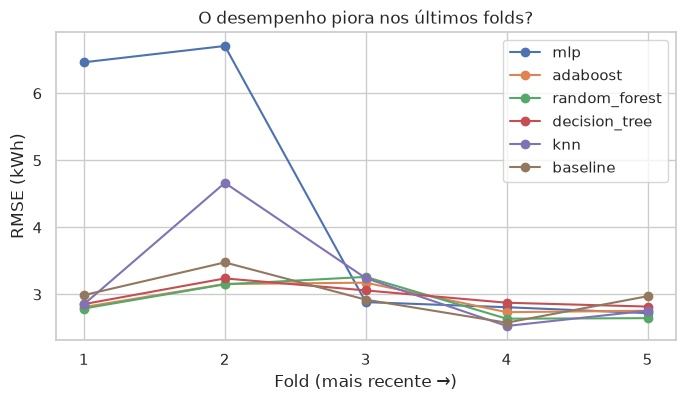

,1,2,3,4,5
mlp,6.46,6.71,2.89,2.81,2.72
adaboost,2.81,3.16,3.18,2.74,2.76
random_forest,2.79,3.15,3.26,2.64,2.65
decision_tree,2.86,3.24,3.06,2.88,2.82
knn,2.85,4.66,3.24,2.53,2.76
baseline,2.99,3.48,2.92,2.58,2.97


In [17]:
client = mlflow.MlflowClient()
folds = pd.DataFrame({
    name: [m.value for m in sorted(client.get_metric_history(row["run_id"], "timeseries_fold_rmse"), key=lambda m: m.step)]
    for name, row in children.iterrows()
}, index=range(1, 6)) / 1000

fig, ax = plt.subplots(figsize=(8, 4))
folds.plot(marker="o", ax=ax)
ax.set_xlabel("Fold (mais recente →)")
ax.set_ylabel("RMSE (kWh)")
ax.set_xticks(folds.index)
ax.set_title("O desempenho piora nos últimos folds?")
plt.show()
folds.T

**Interpretação:** não: o erro não piora nos últimos folds, ele melhora. Os folds avançam de janeiro a agosto. Os modelos erram mais nos folds 2 e 3, a entrada da estação chuvosa, que o treino daquele momento (só verão) ainda não tinha visto. Nos folds 4 e 5 o treino já inclui meses de chuva e o erro cai, mesmo testando no auge do inverno. O baseline físico tem uma curva mais plana: como só aprende o PR, sofre menos com a mudança de estação e chega a vencer os modelos no fold 3 (2,92 kWh). O MLP é o mais sensível a pouco dado: erra 6,5 kWh no 1º fold e 6,7 kWh no 2º, e só se equipara aos outros a partir do 3º. O KNN também tropeça no 2º fold (4,7 kWh).

### Visualização 11: campeão no teste (real × previsto)

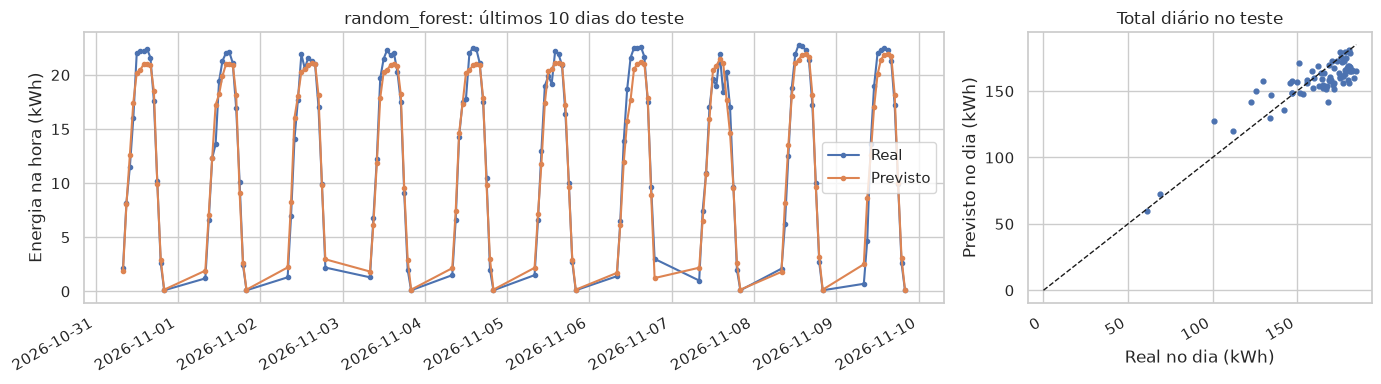

radiation_wh_m2   0.95
air_temp_c        0.02
day_of_year_cos   0.01
day_of_year_sin   0.01
hour              0.01
dtype: float64

In [18]:
champion_run = children.loc[parent["params.champion"], "run_id"]
model = mlflow.sklearn.load_model(f"runs:/{champion_run}/model")
test = df[df["local_date"] >= pd.to_datetime(parent["params.test_period"].split("..")[0]).date()]
pred = model.predict(test[FEATURE_COLUMNS])
last = test["local_date"] >= sorted(test["local_date"].unique())[-10]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [2.5, 1]})
ax1.plot(test.index[last], test.loc[last, TARGET_COLUMN] / 1000, ".-", label="Real")
ax1.plot(test.index[last], pred[last.to_numpy()] / 1000, ".-", label="Previsto")
ax1.set_ylabel("Energia na hora (kWh)")
ax1.set_title(f"{parent['params.champion']}: últimos 10 dias do teste")
ax1.legend()
daily_test = pd.DataFrame({"real": test[TARGET_COLUMN].to_numpy(), "previsto": pred, "dia": test["local_date"].to_numpy()}).groupby("dia").sum() / 1000
ax2.scatter(daily_test["real"], daily_test["previsto"], s=12)
top = daily_test.to_numpy().max()
ax2.plot([0, top], [0, top], "k--", linewidth=1)
ax2.set_xlabel("Real no dia (kWh)")
ax2.set_ylabel("Previsto no dia (kWh)")
ax2.set_title("Total diário no teste")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

importances = pd.Series(model.named_steps["model"].feature_importances_, index=FEATURE_COLUMNS).sort_values(ascending=False)
importances

**Interpretação:** no teste, o modelo acompanha bem o formato de cada dia e erra mais nos picos e nos dias de nuvem passageira: a Open-Meteo é um modelo meteorológico em grade de alguns quilômetros, com um valor por hora, e não enxerga uma nuvem isolada passando sobre os painéis. No total diário, os pontos ficam perto da diagonal, com leve tendência a subestimar os dias de geração mais alta. A radiação responde por 95% da importância das features. Como alerta a aula 14, importância não é causalidade: a temperatura do ar aparece baixa porque o que ela informa já está na radiação.

### Visualização 12: resíduos do campeão no teste

Resíduo = real − previsto (positivo: o modelo subestimou). Um bom modelo tem resíduo centrado em zero, sem padrão
por hora do dia ou por mês e sem abrir conforme a previsão cresce. Os mesmos gráficos ficam no MLflow de cada
modelo (`plots/residuals.png`); aqui vêm as previsões de teste salvas pelo treino (`test_predictions.csv`).

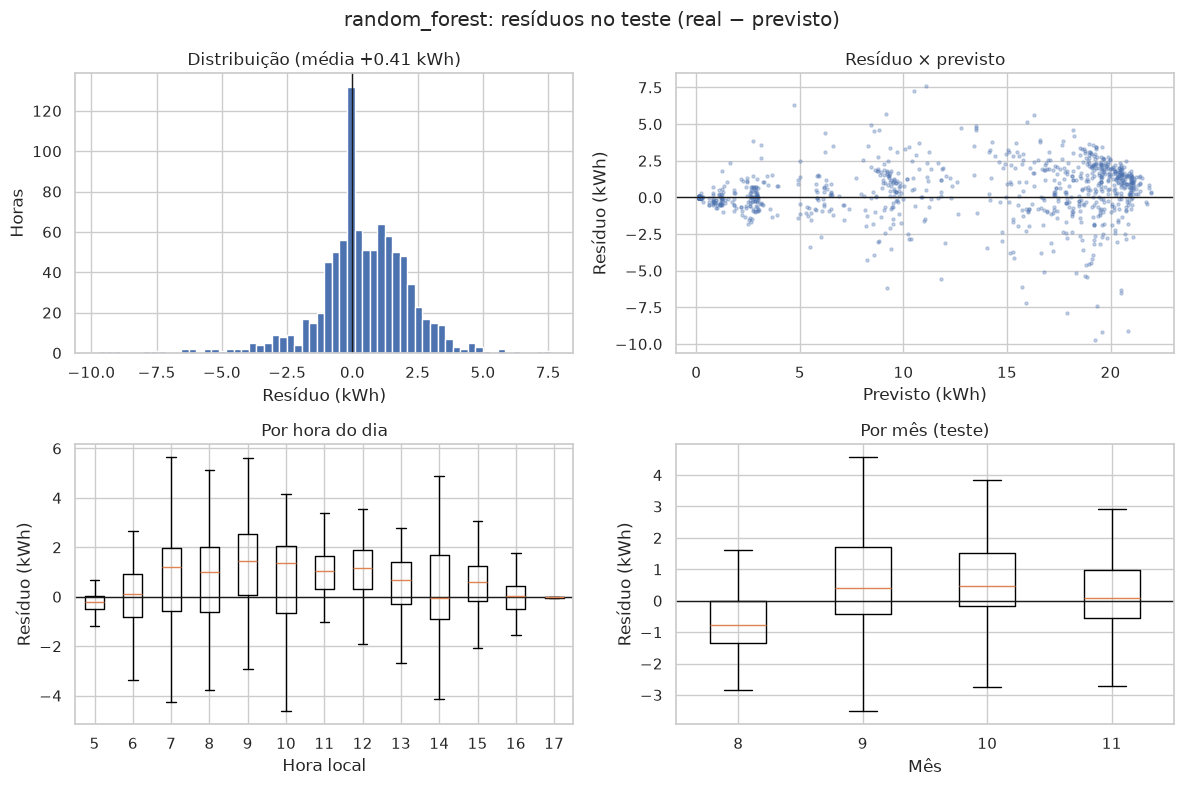

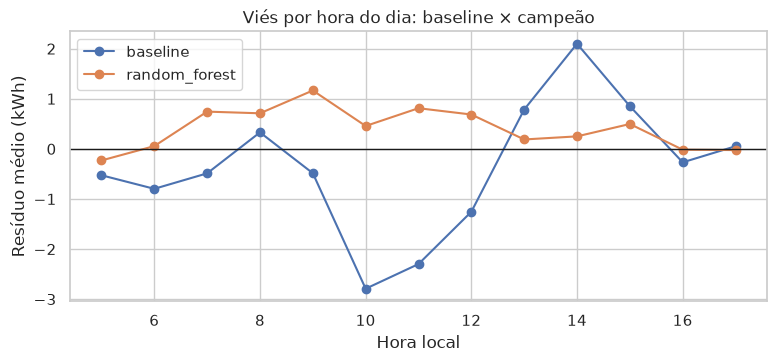

,média (kWh),desvio (kWh),|resíduo| > 3 kWh (%)
baseline,-0.37,2.41,19.52
random_forest,0.41,1.87,10.20


In [19]:
from evaluation import plot_residuals
%matplotlib inline

predictions = pd.read_csv(client.download_artifacts(parent["run_id"], "test_predictions.csv"), index_col=0, parse_dates=True)
champion = parent["params.champion"]
residual_test = test.loc[predictions.index]
residual = predictions["real_wh"] - predictions[champion]
plot_residuals(residual_test, residual.to_numpy(), predictions[champion].to_numpy(), f"{champion}: resíduos no teste (real − previsto)")
plt.show()

stats = pd.DataFrame({
    name: {"média (kWh)": r.mean() / 1000, "desvio (kWh)": r.std() / 1000, "|resíduo| > 3 kWh (%)": (r.abs() > 3000).mean() * 100}
    for name, r in {"baseline": predictions["real_wh"] - predictions["baseline"], champion: residual}.items()
}).T
by_hour = pd.DataFrame({
    "baseline": (predictions["real_wh"] - predictions["baseline"]).groupby(residual_test["hour"].to_numpy()).mean() / 1000,
    champion: residual.groupby(residual_test["hour"].to_numpy()).mean() / 1000,
})
fig, ax = plt.subplots(figsize=(9, 3.5))
by_hour.plot(marker="o", ax=ax)
ax.axhline(0, color="k", linewidth=1)
ax.set_xlabel("Hora local")
ax.set_ylabel("Resíduo médio (kWh)")
ax.set_title("Viés por hora do dia: baseline × campeão")
plt.show()
stats.round(2)

**Interpretação:** o resíduo do Random Forest é centrado perto de zero (média de +0,41 kWh, ou seja, subestima um pouco) e tem desvio de 1,9 kWh, contra 2,4 kWh do baseline. Horas com erro acima de 3 kWh caem de 20% para 10%. Há três padrões a registrar:

- **Por hora do dia,** o baseline tem um viés claro: superestima de 10h a 12h (até 2,8 kWh) e subestima às 14h (2,1 kWh). Ele usa a radiação no plano horizontal e não sabe para onde os painéis estão voltados. O Random Forest aprende essa assimetria com a feature "hora", e o viés dele fica abaixo de 1,2 kWh em todas as horas. É esse o ganho do ML sobre a conta física.
- **Resíduo × previsto:** a dispersão cresce com a previsão (heteroscedasticidade). Perto de 20 kWh, os erros grandes são negativos, horas em que a Open-Meteo previa sol e uma nuvem passou. As horas de pouca geração quase não erram.
- **Por mês,** agosto fica abaixo de zero e setembro a novembro levemente acima. O teste é o fim da estação seca, mais ensolarado que a média do treino, e o modelo é um pouco conservador nesse período. Com mais de um ano de dados, cada estação aparece mais de uma vez e esse viés tende a cair.

### Visualização 13: as outras variáveis do clima ajudam?

A Open-Meteo também traz umidade, pressão, vento e chuva, sem buracos. Mesmo Random Forest (300 árvores,
`min_samples_leaf=5`) e mesmo TimeSeriesSplit do treino, mudando só o conjunto de features.

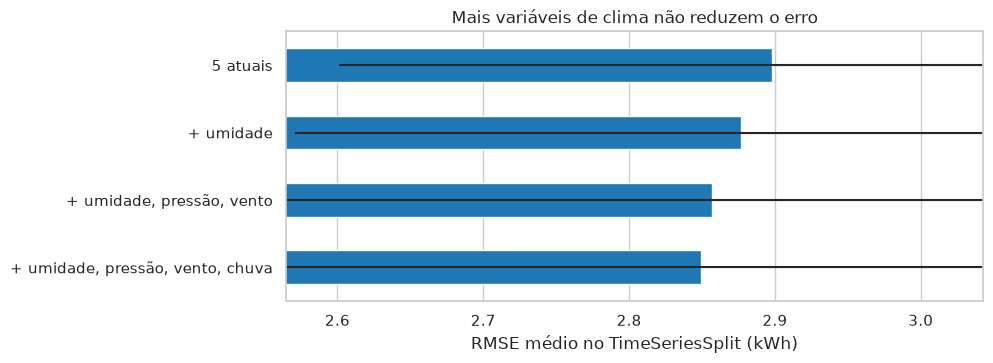

,1,2,3,4,5,média
5 atuais,2.79,3.15,3.27,2.64,2.64,2.90
+ umidade,2.76,3.16,3.25,2.59,2.63,2.88
"+ umidade, pressão, vento",2.73,3.12,3.23,2.60,2.61,2.86
"+ umidade, pressão, vento, chuva",2.73,3.12,3.20,2.59,2.60,2.85


In [20]:
train_part = df[df["local_date"] < pd.to_datetime(parent["params.test_period"].split("..")[0]).date()]
feature_sets = {
    "5 atuais": FEATURE_COLUMNS,
    "+ umidade": FEATURE_COLUMNS + ["humidity_pct"],
    "+ umidade, pressão, vento": FEATURE_COLUMNS + ["humidity_pct", "pressure_hpa", "wind_speed_m_s"],
    "+ umidade, pressão, vento, chuva": FEATURE_COLUMNS + ["humidity_pct", "pressure_hpa", "wind_speed_m_s", "precipitation_mm"],
}
fold_rmse = {}
for name, cols in feature_sets.items():
    X, y = train_part[cols], train_part[TARGET_COLUMN]
    fold_rmse[name] = []
    for tr, te in TimeSeriesSplit(5).split(X):
        rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=42, n_jobs=-1).fit(X.iloc[tr], y.iloc[tr])
        fold_rmse[name].append(np.sqrt(np.mean((y.iloc[te] - rf.predict(X.iloc[te])) ** 2)) / 1000)
fold_rmse = pd.DataFrame(fold_rmse, index=range(1, 6))

fig, ax = plt.subplots(figsize=(9, 3.5))
fold_rmse.mean().sort_values().plot.barh(xerr=fold_rmse.std(), ax=ax, color="tab:blue")
ax.set_xlabel("RMSE médio no TimeSeriesSplit (kWh)")
ax.set_xlim(fold_rmse.mean().min() * 0.9, fold_rmse.mean().max() * 1.05)
ax.set_title("Mais variáveis de clima não reduzem o erro")
plt.show()
fold_rmse.T.assign(média=fold_rmse.mean())

**Interpretação:** não. Com umidade, pressão, vento e chuva, o RMSE médio fica entre 2,85 e 2,88 kWh, contra 2,90 kWh com as 5 features atuais. A diferença é menor que a variação entre os folds (desvio de cerca de 0,25 kWh), ou seja, é ruído. Isso bate com a visualização 6: essas variáveis repetem o que a radiação e a temperatura já informam. Pelo princípio da parcimônia, o modelo fica com as 5 features, o que também simplifica a troca futura pelos sensores da ESP.

## 6. Conclusões

- Com radiação e temperatura do ar da Open-Meteo, mais hora e época do ano, os modelos explicam cerca de 93% da variação da energia horária no teste (R² de 0,93 a 0,94). O erro no total do dia fica entre 6,7% e 8,1% (MAPE diário). O campeão é o Random Forest.
- O **baseline físico** (radiação × 36 kWp × PR de 0,71) é forte, porque a radiação explica quase tudo. O campeão erra 22% menos no teste e 3% menos no TimeSeriesSplit. O ganho vem de corrigir o que a conta física não sabe, principalmente a orientação dos painéis (o viés por hora do dia da visualização 12). Com pouco dado, o baseline é tão bom quanto os modelos.
- A **fonte do clima** importou mais que a escolha do modelo. A estação do INMET em Palmares, a ~100 km, via outro céu em muitos dias; trocar pela Open-Meteo nas coordenadas da usina reduziu o RMSE do TimeSeriesSplit de 3,43 para cerca de 2,9 kWh.
- A **validação temporal** foi decisiva. As divisões aleatórias (KFold embaralhado, um dia fora) dão um erro otimista, e o TimeSeriesSplit mostra que o modelo precisa ter visto a estação chuvosa para prevê-la.
- O **tratamento dos dados** também pesou: remover dias de pane, saltos do contador e horas de contador parado ou lento evitou que falhas do inversor fossem ensinadas como efeito do clima. Os buracos de conexão foram reconstruídos pelo contador diário do inversor só para o dashboard (o total de cada dia bate com o do inversor) e ficaram fora do treino.
- **Limites do modelo temporário:**
  - a Open-Meteo é dado de modelo meteorológico, não medição no local, e não vê nuvens passageiras;
  - os resíduos crescem com a geração e o modelo subestima um pouco a estação seca;
  - há só um ano de dados, ou seja, cada estação aparece uma única vez.
- **Próximo passo:** com a ESP instalada na usina, as features passam a ser medidas no próprio local (irradiância, temperatura do painel e do ar, umidade), em intervalos menores. O mesmo pipeline (`features.py` + `train.py`) é reaproveitado, trocando a fonte das features.